In [1]:
!pip install -q transformers datasets scikit-learn pandas matplotlib seaborn accelerate

In [2]:
import torch
import transformers
import pandas as pd
import sklearn

print("GPU available:", torch.cuda.is_available())
print("Transformers version:", transformers.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
Transformers version: 5.19.0
GPU: Tesla T4


In [3]:
from datasets import load_dataset

dataset = load_dataset("EleutherAI/twitter-sentiment", split="train")
df = dataset.to_pandas()

print(df.shape)
print(df.columns.tolist())
display(df.head())

(1568627, 4)
['label', 'source', 'text', 'id']


,label,source,text,id
0,1,Sentiment140,Last study day tomorrow before my last exam ;o...,1021104
1,0,Sentiment140,@luislanz the iphone 2g only supports bt audio...,345503
2,1,Sentiment140,@alejandradd IT IS!!! And YOU live in South ...,35594
3,0,Sentiment140,merlin is a funny show...i have maths exam thi...,1061354
4,1,Sentiment140,"@ConverseSniffer Heyyyy, I'm a....... Twittere...",93408


In [4]:
import random
import numpy as np
import torch

# Assignment values
SID4 = 2733
SEED = SID4
SLICE = SID4 % 1000

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Select up to 5,000 consecutive rows
start_row = SLICE
end_row = min(start_row + 5000, len(df))

work_df = df.iloc[start_row:end_row].copy()

print("SEED:", SEED)
print("SLICE:", SLICE)
print("Selected rows:", len(work_df))
print("Zero-based row range:", start_row, "through", end_row - 1)
print("Labels:", work_df["label"].value_counts().to_dict())

display(work_df.head())

SEED: 2733
SLICE: 733
Selected rows: 5000
Zero-based row range: 733 through 5732
Labels: {1: 2557, 0: 2443}


,label,source,text,id
733,1,Sentiment140,"original material RB@Ganjagod. yes, this was ...",1518359
734,1,Sentiment140,watching the movie awards on mtv germany - way...,1305616
735,1,Sentiment140,Yahoo Answers is rather lolable,1347451
736,0,Sentiment140,@thomas rofl. did you create the ringtone your...,518587
737,1,Sentiment140,@Bytemarks ugh...had to get away from that sit...,119148


In [5]:
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer
import torch
from torch.utils.data import TensorDataset

# Recreate the required 70/15/15 split
train_df, temp_df = train_test_split(
    work_df,
    test_size=0.30,
    random_state=SEED,
    stratify=work_df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Load BERT tokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
MAX_LENGTH = 128

def create_tensor_dataset(dataframe):
    encoded = tokenizer(
        dataframe["text"].astype(str).tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    labels = torch.tensor(
        dataframe["label"].astype(int).tolist(),
        dtype=torch.long
    )

    return TensorDataset(
        encoded["input_ids"],
        encoded["attention_mask"],
        labels
    )

train_dataset = create_tensor_dataset(train_df)
val_dataset = create_tensor_dataset(val_df)
test_dataset = create_tensor_dataset(test_df)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))
print("Input shape:", train_dataset.tensors[0].shape)

Training dataset: 3500
Validation dataset: 750
Test dataset: 750
Input shape: torch.Size([3500, 128])


In [6]:
from transformers import BertForSequenceClassification
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Device:", device)
print("Model initialized successfully")
print("Number of labels:", model.num_labels)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device: cuda
Model initialized successfully
Number of labels: 2


In [7]:
import time
import torch

from torch.optim import AdamW

# Reproducibility
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

EPOCHS = 3
LEARNING_RATE = 2e-5

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
training_start = time.perf_counter()

for epoch in range(EPOCHS):
    # Training
    model.train()
    total_train_loss = 0

    for batch in train_loader:
        input_ids, attention_mask, labels = [
            item.to(device) for item in batch
        ]

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    average_train_loss = total_train_loss / len(train_loader)

    # Validation
    model.eval()
    total_val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch in val_loader:
            input_ids, attention_mask, labels = [
                item.to(device) for item in batch
            ]

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_val_loss += outputs.loss.item()

            predictions = torch.argmax(outputs.logits, dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_val_loss = total_val_loss / len(val_loader)
    validation_accuracy = correct / total

    history["train_loss"].append(average_train_loss)
    history["val_loss"].append(average_val_loss)
    history["val_accuracy"].append(validation_accuracy)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {average_train_loss:.4f} | "
        f"Validation loss: {average_val_loss:.4f} | "
        f"Validation accuracy: {validation_accuracy:.4f}"
    )

training_time = time.perf_counter() - training_start
peak_gpu_memory_gb = torch.cuda.max_memory_allocated() / (1024 ** 3)

print(f"\nTraining time: {training_time:.2f} seconds")
print(f"Peak GPU memory: {peak_gpu_memory_gb:.2f} GB")

Epoch 1/3 | Train loss: 0.5364 | Validation loss: 0.4357 | Validation accuracy: 0.8133
Epoch 2/3 | Train loss: 0.3540 | Validation loss: 0.4157 | Validation accuracy: 0.8227
Epoch 3/3 | Train loss: 0.1964 | Validation loss: 0.4983 | Validation accuracy: 0.8147

Training time: 221.63 seconds
Peak GPU memory: 3.73 GB


Numeric confusion matrix [rows=true, columns=predicted]:
[[276  90]
 [ 63 321]]
Test accuracy: 0.7960

Classification report:
              precision    recall  f1-score   support

    Negative       0.81      0.75      0.78       366
    Positive       0.78      0.84      0.81       384

    accuracy                           0.80       750
   macro avg       0.80      0.80      0.80       750
weighted avg       0.80      0.80      0.80       750



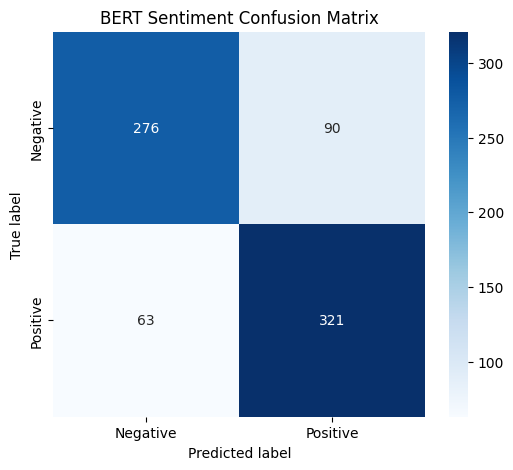

In [8]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        input_ids, attention_mask, labels = [
            item.to(device) for item in batch
        ]

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)
cm = confusion_matrix(all_labels, all_predictions)

print("Numeric confusion matrix [rows=true, columns=predicted]:")
print(cm)

print(f"Test accuracy: {test_accuracy:.4f}")
print("\nClassification report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Negative", "Positive"]
    )
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("BERT Sentiment Confusion Matrix")
plt.show()

In [9]:
# Store predictions alongside the original test examples
test_results = test_df.copy()

test_results["true_label"] = all_labels
test_results["predicted_label"] = all_predictions

# Worst class is Negative = 0
negative_errors = test_results[
    (test_results["true_label"] == 0) &
    (test_results["predicted_label"] == 1)
]

print("Number of misclassified negative examples:", len(negative_errors))

display(
    negative_errors[
        ["text", "true_label", "predicted_label"]
    ].head(5)
)

Number of misclassified negative examples: 90


,text,true_label,predicted_label
6,Beautiful sunshine in Paihia this morning. Rai...,0,1
7,@VoltjanStevens - That leaves less room for bo...,0,1
18,"just learned how to play sudoku, having a glas...",0,1
25,"Dude! Every other person, here, at KFK has a P...",0,1
27,This shift will b over in two hours....can't w...,0,1


In [21]:
for i, t in enumerate(negative_errors["text"].head(5), 1):
    print(f"{i}. {t}\n")

1. Beautiful sunshine in Paihia this morning. Rain in Auckland tonight. Holiday over 

2. @VoltjanStevens - That leaves less room for books and yarn. 

3. just learned how to play sudoku, having a glass of wine, chillin, as there is a 10 hour day in store for me tomorrow 

4. Dude! Every other person, here, at KFK has a PSP. Apparently, I'm not one of them. 

5. This shift will b over in two hours....can't wait to go home &amp; spend some time w/ my guys...B4 i have to turn around &amp; b right back here 



## Five Misclassified Examples from the Worst Class

The worst class was **Negative**, with the lowest recall (0.75): 90 of 366 negative test tweets were predicted Positive. Texts below are verbatim from the test set.

1. `Beautiful sunshine in Paihia this morning. Rain in Auckland tonight. Holiday over`
   Diagnosis: Strong positive words ("Beautiful sunshine") dominate, while the negative meaning ("Holiday over") is stated flatly with no emotional words.

2. `@VoltjanStevens - That leaves less room for books and yarn.`
   Diagnosis: The complaint is implied by context with no sentiment words, so the model has no negative cue to latch onto.

3. `just learned how to play sudoku, having a glass of wine, chillin, as there is a 10 hour day in store for me tomorrow`
   Diagnosis: Relaxed, positive activities fill most of the tweet; the negative part (a long workday ahead) is factual, not emotional.

4. `Dude! Every other person, here, at KFK has a PSP. Apparently, I'm not one of them.`
   Diagnosis: The disappointment is expressed through ironic understatement ("Apparently, I'm not one of them"), which the model reads literally.

5. `This shift will b over in two hours....can't wait to go home &amp; spend some time w/ my guys...B4 i have to turn around &amp; b right back here`
   Diagnosis: "can't wait to go home" reads as strongly positive, and the negative twist is buried in slang and abbreviations ("B4", "b", "w/") at the end.

In [10]:
save_directory = "/content/bert_twitter_sentiment"

model.save_pretrained(save_directory)
tokenizer.save_pretrained(save_directory)

reloaded_model = BertForSequenceClassification.from_pretrained(
    save_directory
).to(device)

reloaded_model.eval()

print("Model and tokenizer saved and reloaded successfully.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model and tokenizer saved and reloaded successfully.


In [11]:
# Custom BERT inference using the reloaded fine-tuned model
custom_tweets = [
    "I absolutely loved this movie; it made my whole day!",
    "This is the worst customer service I have ever experienced."
]

encoded_custom = tokenizer(
    custom_tweets,
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt"
).to(device)

with torch.no_grad():
    custom_outputs = reloaded_model(**encoded_custom)

custom_predictions = torch.argmax(custom_outputs.logits, dim=1).cpu().tolist()
label_names = {0: "Negative", 1: "Positive"}

for tweet, prediction in zip(custom_tweets, custom_predictions):
    print(f"Tweet: {tweet}")
    print(f"Predicted sentiment: {label_names[prediction]}\n")


Tweet: I absolutely loved this movie; it made my whole day!
Predicted sentiment: Positive

Tweet: This is the worst customer service I have ever experienced.
Predicted sentiment: Negative



## Training Curve Summary

Validation performance stopped improving after **Epoch 2**, which had the best validation loss (0.4157) and validation accuracy (0.8227). Training continued through Epoch 3; the training loss fell to 0.1964, but validation loss worsened to 0.4983 and validation accuracy fell to 0.8147.

The extra epoch cost about 74 s (~1/3 of the 221.63 s run) and made the model worse (val loss +20%). No best checkpoint was kept, so the test results (accuracy 0.7960) come from the overfit Epoch 3 weights.

**HW4.5 baseline:** peak GPU memory 3.73 GB, wall-clock training time 221.63 s (3 epochs, batch 32, max length 128, fp32, Tesla T4).

The working subset contains 5,000 consecutive rows, zero-based rows **733 through 5732 inclusive**, split into 3,500 training, 750 validation, and 750 test examples using SEED = 2733.

In [12]:
!pip uninstall -y vllm triton
!pip install -q --no-cache-dir \
    "torch==2.13.0" \
    "vllm==0.32.0" \
    "transformers<5.20.0"

Found existing installation: vllm 0.32.0
Uninstalling vllm-0.32.0:
  Successfully uninstalled vllm-0.32.0
Found existing installation: triton 3.7.1
Uninstalling triton-3.7.1:
  Successfully uninstalled triton-3.7.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 MB 171.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 197.7/197.7 MB 201.1 MB/s eta 0:00:00


In [13]:
import torch

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

import vllm

print("vLLM:", vllm.__version__)

PyTorch: 2.13.0+cu130
GPU: Tesla T4
vLLM: 0.32.0


In [15]:
import gc
import torch

for name in ["model", "reloaded_model"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()
print("GPU cache cleared before vLLM")

from vllm import LLM, SamplingParams

VLLM_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"

llm = LLM(
    model=VLLM_MODEL,
    dtype="float16",
    max_model_len=512,
    gpu_memory_utilization=0.80,
    enforce_eager=True
)

sampling_params = SamplingParams(
    temperature=0.7,
    top_p=0.9,
    max_tokens=80
)

prompt = """
Explain in simple terms how sentiment analysis works
and give one example using a tweet.
"""

outputs = llm.generate([prompt], sampling_params)
print(outputs[0].outputs[0].text)

GPU cache cleared before vLLM
(MainProcess pid=5928) INFO 10-22 04:57:08 [api_utils.py:286] non-default args: {'dtype': 'float16', 'max_model_len': 512, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
(MainProcess pid=5928) INFO 10-22 04:57:08 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=5928) WARNING 10-22 04:57:08 [model.py:2498] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=5928) INFO 10-22 04:57:08 [model.py:2152] Using max model len 512
(MainProcess pid=5928) INFO 10-22 04:57:08 [kernel.py:467] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['vllm_c', 'native'], fused_add_rms_norm=['vllm_c', 'native'], gelu_and_mul_sparse=['triton', 'native'])
(MainProcess pid=5928) INFO 10-22 04:58:20 [hf.py:648] Detected the chat template content format to be 'string'. You can set `--chat-template-content-format` to override this.


Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:07<00:00,  7.30s/it, est. speed input: 2.60 toks/s, output: 10.97 toks/s]

Sentiment analysis is a type of natural language processing (NLP) that involves analyzing the emotional tone or sentiment of a piece of text. Sentiment analysis is used to determine the emotional state of a person or thing based on the words and phrases used in the text.
For example, if you saw the tweet "I just got a new job! I'm so excited! " the sentiment would be


In [16]:
import time
import numpy as np

benchmark_sampling = SamplingParams(
    temperature=0.0,
    max_tokens=32
)

benchmark_prompt = (
    "Analyze the sentiment of this tweet and answer Positive or Negative: "
    "I had a wonderful day and everything went perfectly."
)

def benchmark_vllm(batch_size, repeats=10):
    prompts = [benchmark_prompt] * batch_size

    # Warm-up run
    llm.generate(
        prompts,
        benchmark_sampling,
        use_tqdm=False
    )

    latencies = []
    total_tokens = 0
    total_time = 0

    for _ in range(repeats):
        start = time.perf_counter()

        outputs = llm.generate(
            prompts,
            benchmark_sampling,
            use_tqdm=False
        )

        elapsed = time.perf_counter() - start
        latencies.append(elapsed * 1000)
        total_time += elapsed

        total_tokens += sum(
            len(output.outputs[0].token_ids)
            for output in outputs
        )

    return {
        "batch_size": batch_size,
        "tokens_per_second": total_tokens / total_time,
        "p50_latency_ms": np.percentile(latencies, 50),
        "p95_latency_ms": np.percentile(latencies, 95)
    }

vllm_results = []

for batch_size in [1, 8, 32]:
    result = benchmark_vllm(batch_size)
    vllm_results.append(result)
    print(result)

{'batch_size': 1, 'tokens_per_second': 34.845666610823464, 'p50_latency_ms': np.float64(919.3492914999979), 'p95_latency_ms': np.float64(943.009324699949)}
{'batch_size': 8, 'tokens_per_second': 266.1660083771921, 'p50_latency_ms': np.float64(953.7268619999395), 'p95_latency_ms': np.float64(1001.8917518000194)}
{'batch_size': 32, 'tokens_per_second': 1001.1499914691285, 'p50_latency_ms': np.float64(1024.8719599999276), 'p95_latency_ms': np.float64(1040.8422958999495)}


| Configuration | Tokens/sec | p50 latency (ms) | p95 latency (ms) |
|---|---:|---:|---:|
| HF pipeline, batch 1 | 25.76 | 1199.01 | 1436.04 |
| vLLM, batch 1 | 34.85 | 919.35 | 943.01 |
| vLLM, batch 8 | 266.17 | 953.73 | 1001.89 |
| vLLM, batch 32 | 1001.15 | 1024.87 | 1040.84 |

In [17]:
import gc
import torch

del llm
gc.collect()
torch.cuda.empty_cache()

print("GPU cache cleared")

(MainProcess pid=5928) INFO 10-22 04:59:58 [utils.py:628] [shutdown] Process manager: send sigterm to process EngineCore
GPU cache cleared


In [18]:
from transformers import pipeline
import time
import numpy as np
import torch

HF_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"

hf_pipeline = pipeline(
    "text-generation",
    model=HF_MODEL,
    device=0,
    torch_dtype=torch.float16
)

prompt = (
    "Analyze the sentiment of this tweet and answer Positive or Negative: "
    "I had a wonderful day and everything went perfectly."
)

# Warm-up
hf_pipeline(
    prompt,
    max_new_tokens=32,
    do_sample=False,
    return_full_text=False
)

latencies = []
total_tokens = 0
total_time = 0

for _ in range(10):
    start = time.perf_counter()

    result = hf_pipeline(
        prompt,
        max_new_tokens=32,
        do_sample=False,
        return_full_text=False
    )

    elapsed = time.perf_counter() - start
    latencies.append(elapsed * 1000)
    total_time += elapsed

    generated_text = result[0]["generated_text"]
    total_tokens += len(
        hf_pipeline.tokenizer.encode(
            generated_text,
            add_special_tokens=False
        )
    )

hf_result = {
    "configuration": "HF pipeline, batch 1",
    "tokens_per_second": total_tokens / total_time,
    "p50_latency_ms": np.percentile(latencies, 50),
    "p95_latency_ms": np.percentile(latencies, 95)
}

print(hf_result)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=32) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=32) a

{'configuration': 'HF pipeline, batch 1', 'tokens_per_second': 25.761994875888455, 'p50_latency_ms': np.float64(1199.0123675000177), 'p95_latency_ms': np.float64(1436.038209299954)}


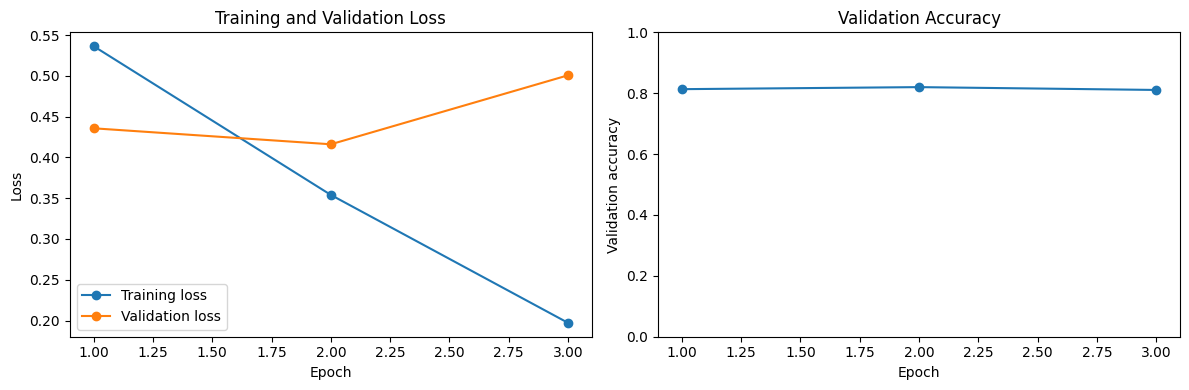

In [20]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], marker="o", label="Training loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, history["val_accuracy"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Validation Accuracy")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

## Table HW4.1 Serving Comparison

| Configuration | Tokens/sec | p50 latency (ms) | p95 latency (ms) |
|---|---:|---:|---:|
| HF pipeline, batch 1 | 25.76 | 1199.01 | 1436.04 |
| vLLM, batch 1 | 34.85 | 919.35 | 943.01 |
| vLLM, batch 8 | 266.17 | 953.73 | 1001.89 |
| vLLM, batch 32 | 1001.15 | 1024.87 | 1040.84 |


## Serving Analysis

None of the tested vLLM batch sizes became slower than the Hugging Face batch-1 baseline: the baseline p50/p95 latencies were 1199.01/1436.04 ms, while vLLM remained lower at batches 1, 8, and 32. Per-request latency increased slightly from vLLM batch 1 to batches 8 and 32, while total throughput improved from 34.85 to 1001.15 tokens/sec. For an interactive application, p95 latency matters more because it captures the slower requests users may experience. For offline or high-volume processing, total throughput is the more important metric.